# Proyecto Integrador de Ciencia de Datos
## Fase 2, actividad 4: Partición de datos y modelo base (Entregable 2)

**Universidad de La Salle**, Maestría en Inteligencia Artificial
**Asignatura:** Ciencia de Datos (2026-2). **Docente:** Fabián Camilo Castro Riveros
**Estudiante:** Martín Gracia Socha (trabajo individual)
**Conjunto de datos:** METABRIC

> Este cuaderno continúa `02_Limpieza_Ingenieria_Variables.ipynb`. Ambos forman el Entregable 2: el 02 cubre limpieza, imputación, atípicos, variables derivadas y codificación sin fuga; este cubre la partición, el desbalance de clases y los modelos base.

### Contenido
1. Configuración del entorno
2. Requisitos del Entregable 2 y dónde se cumplen
3. Carga y verificación de reproducibilidad
4. Validación de la partición
5. Análisis y tratamiento del desbalance de clases
6. Modelo base de regresión (NPI)
7. Modelo base de clasificación (PAM50)
8. Diagnóstico de sobreajuste
9. Umbral mínimo de desempeño
10. Conclusiones y siguientes pasos

## 1. Configuración del entorno

In [1]:
import sys
import json
import warnings
from pathlib import Path

# --- Entorno: en Google Colab se clona el repositorio y se instalan dependencias faltantes ---
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/MartinGia/metabric-proyecto-integrador.git"
if IN_COLAB:
    # En Colab se clona el repositorio (datos, código y modelos) y se instalan las librerías que Colab no trae.
    import os, subprocess, importlib.util
    repo_dir = Path("/content/metabric-proyecto-integrador")
    if not (repo_dir / "src" / "config.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir / "notebooks")
    for pkg, module in [("imbalanced-learn", "imblearn"), ("xgboost", "xgboost"), ("shap", "shap")]:
        if importlib.util.find_spec(module) is None:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

def find_project_root():
    for c in [Path.cwd(), *Path.cwd().parents]:
        if (c / "src" / "config.py").exists():
            return c
    raise FileNotFoundError("No se encontró la carpeta del proyecto (debe contener src/config.py). "
                            "Abra el notebook desde la carpeta notebooks/ del repositorio.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, learning_curve
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# --- Localización de la raíz del proyecto (carpeta que contiene src/config.py) ---
ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config
from src.cleaning import clean_metabric
from src.features import add_derived_features
from src.preprocessing import make_splits, build_preprocessor, all_columns
from src.modeling import (load_processed, task_data, regression_metrics, classification_metrics,
                          cv_regression, cv_classification, CLASS_ORDER)

config.ensure_dirs()
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
SEED = config.RANDOM_STATE
np.random.seed(SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def savefig(name):
    plt.savefig(config.FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

print("Carpeta del proyecto:", ROOT.name)

Carpeta del proyecto: repo


## 2. Requisitos del Entregable 2 y dónde se cumplen

| Requisito de la guía (Fase 2) | Dónde se cumple |
|---|---|
| Justificación del tratamiento de faltantes analizando MCAR, MAR o MNAR | Cuaderno 02, secciones 4 y 10 |
| Tratamiento razonado de atípicos (log, winsorización) | Cuaderno 02, sección 6 |
| Al menos 2 variables derivadas con respaldo del dominio | Cuaderno 02, sección 7 (11 variables) |
| Codificación de categóricas sin fuga | Cuaderno 02, sección 11 (`OneHotEncoder` dentro del pipeline) |
| Escalamiento ajustado solo con entrenamiento | Cuaderno 02, sección 11, y este cuaderno (todos los modelos usan `Pipeline`) |
| Partición entrenamiento (70-80 %), validación y prueba, estratificada en clasificación | Cuaderno 02, sección 9, y este cuaderno, sección 4 |
| Tratamiento del desbalance si aplica (SMOTE, ADASYN o `class_weight`) | Este cuaderno, sección 5 |
| Modelo base: regresión lineal simple o regresión logística básica / *Dummy* | Este cuaderno, secciones 6 y 7 |

**Regla de uso de los subconjuntos.** La selección de modelos y la estimación de su variabilidad se hacen con validación cruzada (5 particiones) **dentro de entrenamiento**; la validación sirve para comparar modelos ya ajustados; la **prueba no se usa en esta fase** y se reserva para la evaluación final de la fase 3.

## 3. Carga y verificación de reproducibilidad

In [2]:
df, FS = load_processed()
print(f"Datos procesados: {df.shape[0]:,} filas × {df.shape[1]} columnas")

# 1) La limpieza y la partición se pueden regenerar desde los datos crudos con el mismo resultado
raw = pd.read_csv(config.RAW_FILE, low_memory=False)
regen = add_derived_features(clean_metabric(raw)[0])
regen_split = make_splits(regen, config.TARGET_CLASSIFICATION)
print("Partición regenerada idéntica a la guardada:", bool((regen_split.to_numpy() == df["split"].to_numpy()).all()))

# 2) Ninguna paciente aparece en más de un subconjunto
ids = {s: set(df.loc[df.split == s, "patient_id"]) for s in ["train", "val", "test"]}
print("Pacientes compartidas train-val:", len(ids["train"] & ids["val"]),
      "| train-test:", len(ids["train"] & ids["test"]), "| val-test:", len(ids["val"] & ids["test"]))

Datos procesados: 1,903 filas × 704 columnas


Partición regenerada idéntica a la guardada: True
Pacientes compartidas train-val: 0 | train-test: 0 | val-test: 0


## 4. Validación de la partición

In [3]:
reg_df, y_reg = task_data(df, "regression")
clf_df, y_clf = task_data(df, "classification")
sizes = pd.DataFrame({
    "todas": df["split"].value_counts(),
    "regresión (npi_valid = 1)": reg_df["split"].value_counts(),
    "clasificación (sin NC)": clf_df["split"].value_counts(),
}).loc[["train", "val", "test"]]
sizes.loc["total"] = sizes.sum()
display(pd.concat({"n": sizes, "%": (100 * sizes / sizes.loc["total"]).round(1)}, axis=1))

n                                                        %                                                 
      todas regresión (npi_valid = 1) clasificación (sin NC)   todas regresión (npi_valid = 1) clasificación (sin NC)
split                                                                                                                
train  1332                      1285                   1328  70.000                    69.600                 70.000
val     285                       280                    284  15.000                    15.200                 15.000
test    286                       281                    285  15.000                    15.200                 15.000
total  1903                      1846                   1897 100.000                   100.000                100.000

KS NPI train vs. val: D = 0.034, p = 0.938
KS NPI train vs. test: D = 0.035, p = 0.933


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,"1,285.000",4.101,1.084,2.000,3.050,4.046,5.044,6.360
val,280.000,4.074,1.095,2.002,3.050,4.043,5.040,6.130
test,281.000,4.122,1.050,2.018,3.058,4.046,5.040,6.320


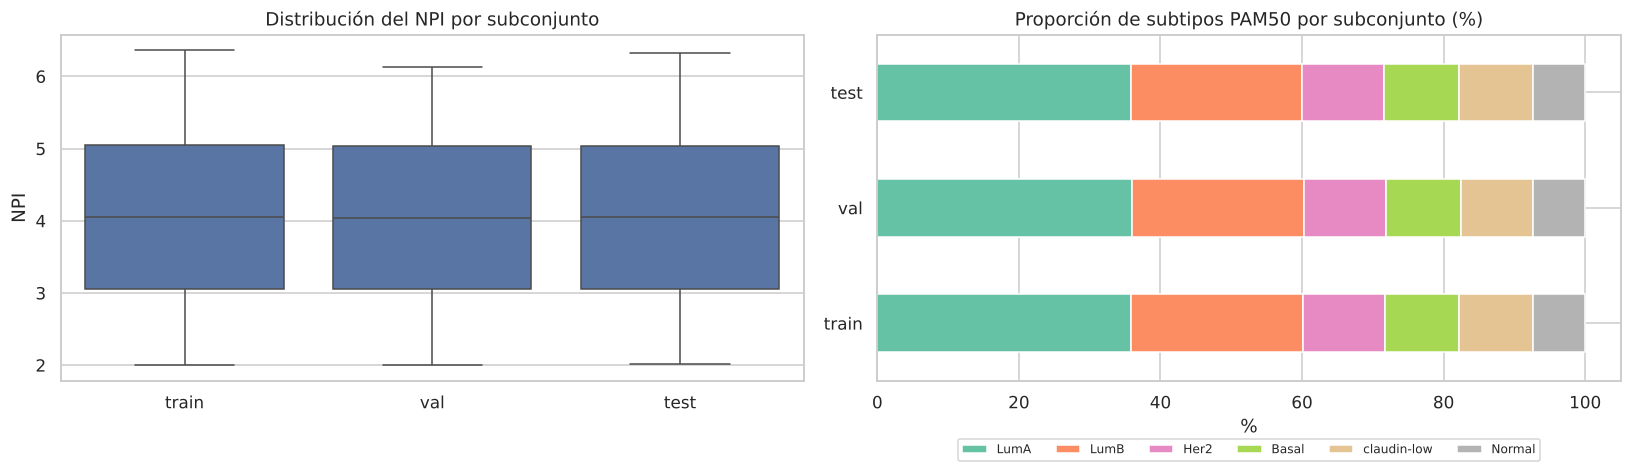

In [4]:
# El objetivo de regresión no está estratificado directamente: se comprueba que su distribución
# sea equivalente entre subconjuntos (Kolmogorov-Smirnov).
tr_npi = reg_df.loc[reg_df.split == "train", y_reg]
for s in ["val", "test"]:
    ks = stats.ks_2samp(tr_npi, reg_df.loc[reg_df.split == s, y_reg])
    print(f"KS NPI train vs. {s}: D = {ks.statistic:.3f}, p = {ks.pvalue:.3f}")
display(reg_df.groupby("split")[y_reg].describe().loc[["train", "val", "test"]])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=reg_df, x="split", y=y_reg, order=["train", "val", "test"], ax=axes[0], color="#4C72B0")
axes[0].set(title="Distribución del NPI por subconjunto", xlabel="", ylabel="NPI")
prop = pd.crosstab(clf_df["split"], clf_df[y_clf], normalize="index").loc[["train", "val", "test"], CLASS_ORDER] * 100
prop.plot(kind="barh", stacked=True, ax=axes[1], colormap="Set2")
axes[1].set(title="Proporción de subtipos PAM50 por subconjunto (%)", xlabel="%", ylabel="")
axes[1].legend(ncol=6, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.tight_layout()
savefig("17_validacion_particion")
plt.show()

## 5. Análisis y tratamiento del desbalance de clases
Se mide el desbalance del subtipo PAM50 en entrenamiento y se comparan, con validación cruzada estratificada, tres estrategias sobre la misma regresión logística básica:

1. Sin tratamiento.
2. `class_weight="balanced"`: pondera cada clase de forma inversa a su frecuencia.
3. **SMOTE**: genera ejemplos sintéticos de las clases minoritarias. Va dentro de un `Pipeline` de *imbalanced-learn*, de modo que se aplica solo al pliegue de entrenamiento de cada partición y nunca al de evaluación.

In [5]:
tr_clf = clf_df[clf_df.split == "train"]
counts = tr_clf[y_clf].value_counts().reindex(CLASS_ORDER)
ratio = counts.max() / counts.min()
display(pd.DataFrame({"n": counts, "%": (100 * counts / counts.sum()).round(1)}).T)
print(f"Razón de desbalance (clase mayoritaria / minoritaria): {ratio:.2f}")
print("Criterio usado: razón < 10 se considera desbalance moderado; >= 10, severo.")

pam50_+_claudin-low_subtype,LumA,LumB,Her2,Basal,claudin-low,Normal
n,475.000,323.000,154.000,139.000,139.000,98.000
%,35.800,24.300,11.600,10.500,10.500,7.400


Razón de desbalance (clase mayoritaria / minoritaria): 4.85
Criterio usado: razón < 10 se considera desbalance moderado; >= 10, severo.


In [6]:
clf_cols = all_columns(FS["classification"])
X_tr_clf, y_tr_clf = tr_clf[clf_cols], tr_clf[y_clf]

def logreg(**kw):
    return LogisticRegression(max_iter=3000, random_state=SEED, **kw)

strategies = {
    "Sin tratamiento": Pipeline([("pre", build_preprocessor(FS["classification"])), ("model", logreg())]),
    "class_weight = balanced": Pipeline([("pre", build_preprocessor(FS["classification"])),
                                         ("model", logreg(class_weight="balanced"))]),
    "SMOTE (k = 5)": ImbPipeline([("pre", build_preprocessor(FS["classification"])),
                                  ("smote", SMOTE(k_neighbors=5, random_state=SEED)), ("model", logreg())]),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for name, pipe in strategies.items():
    res = cross_validate(pipe, X_tr_clf, y_tr_clf, cv=cv,
                         scoring={"F1_macro": "f1_macro", "Balanced_Accuracy": "balanced_accuracy"})
    # Recall por clase con predicciones fuera de pliegue
    pred = cross_val_predict(pipe, X_tr_clf, y_tr_clf, cv=cv)
    rec = pd.Series(classification_report(y_tr_clf, pred, output_dict=True, zero_division=0)).loc[CLASS_ORDER]
    rows.append({"estrategia": name, "_f1": res["test_F1_macro"].mean(), "_f1sd": res["test_F1_macro"].std(),
                 "F1_macro (CV)": f"{res['test_F1_macro'].mean():.3f} ± {res['test_F1_macro'].std():.3f}",
                 "Balanced_Accuracy (CV)": f"{res['test_Balanced_Accuracy'].mean():.3f} ± {res['test_Balanced_Accuracy'].std():.3f}",
                 **{f"recall {c}": rec[c]["recall"] for c in CLASS_ORDER}})
imb = pd.DataFrame(rows).set_index("estrategia")
display(imb.drop(columns=["_f1", "_f1sd"]))

# Regla de decisión: si las diferencias de F1 macro caen dentro de una desviación estándar (empate
# estadístico), se elige la estrategia con mayor recall en la clase minoritaria (Normal).
best_f1 = imb["_f1"].max()
tied = imb[imb["_f1"] >= best_f1 - imb["_f1sd"].max()]
best_strategy = tied["recall Normal"].idxmax()
print(f"Estrategias empatadas en F1 macro (dentro de {imb['_f1sd'].max():.3f}): {', '.join(tied.index)}")
print("Estrategia seleccionada (mayor recall de la clase minoritaria):", best_strategy)

,F1_macro (CV),Balanced_Accuracy (CV),recall LumA,recall LumB,recall Her2,recall Basal,recall claudin-low,recall Normal
estrategia,,,,,,,,
Sin tratamiento,0.701 ± 0.012,0.694 ± 0.016,0.794,0.774,0.675,0.698,0.777,0.449
class_weight = balanced,0.698 ± 0.019,0.697 ± 0.021,0.766,0.771,0.688,0.698,0.777,0.480
SMOTE (k = 5),0.697 ± 0.017,0.696 ± 0.020,0.771,0.777,0.708,0.691,0.763,0.469


Estrategias empatadas en F1 macro (dentro de 0.019): Sin tratamiento, class_weight = balanced, SMOTE (k = 5)
Estrategia seleccionada (mayor recall de la clase minoritaria): class_weight = balanced


## 6. Modelo base de regresión (NPI)
Se entrenan tres referencias, todas dentro de un `Pipeline`:

* **DummyRegressor (media):** predice siempre la media de entrenamiento. Es el piso absoluto: cualquier modelo útil debe superarlo.
* **Regresión lineal simple:** usa un único predictor, el **puntaje de proliferación** (variable derivada en la actividad 3), elegido por su respaldo biológico y por ser el predictor individual más correlacionado con el NPI válido.
* **Regresión lineal múltiple sin regularizar (diagnóstico):** usa los 572 predictores. No es un modelo candidato; se incluye para medir el sobreajuste que aparece sin regularización y justificar el uso de Lasso, Ridge o ElasticNet en la fase 3.

In [7]:
reg_cols = all_columns(FS["regression"])
tr_reg, va_reg = reg_df[reg_df.split == "train"], reg_df[reg_df.split == "val"]

reg_models = {
    "DummyRegressor (media)": (Pipeline([("model", DummyRegressor(strategy="mean"))]), ["age_at_diagnosis"]),
    "Regresión lineal simple (proliferación)": (Pipeline([("impute", SimpleImputer(strategy="median")),
                                                          ("scale", StandardScaler()),
                                                          ("model", LinearRegression())]), ["proliferation_score"]),
    "Regresión lineal múltiple sin regularizar": (Pipeline([("pre", build_preprocessor(FS["regression"])),
                                                            ("model", LinearRegression())]), reg_cols),
}
reg_rows, reg_fitted = [], {}
for name, (pipe, cols) in reg_models.items():
    cvres = cv_regression(pipe, tr_reg[cols], tr_reg[y_reg])
    pipe.fit(tr_reg[cols], tr_reg[y_reg])
    reg_fitted[name] = (pipe, cols)
    m_tr = regression_metrics(tr_reg[y_reg], pipe.predict(tr_reg[cols]))
    m_va = regression_metrics(va_reg[y_reg], pipe.predict(va_reg[cols]))
    reg_rows.append({"modelo": name,
                     "R2 train": m_tr["R2"], "R2 CV": cvres["CV_test_R2_mean"], "R2 CV (desv.)": cvres["CV_test_R2_std"],
                     "R2 val": m_va["R2"], "RMSE CV": cvres["CV_test_RMSE_mean"], "RMSE val": m_va["RMSE"],
                     "MAE CV": cvres["CV_test_MAE_mean"], "MAE val": m_va["MAE"]})
reg_table = pd.DataFrame(reg_rows).set_index("modelo")
reg_table

,R2 train,R2 CV,R2 CV (desv.),R2 val,RMSE CV,RMSE val,MAE CV,MAE val
modelo,,,,,,,,
DummyRegressor (media),0.000,-0.003,0.002,-0.001,1.083,1.094,0.846,0.836
Regresión lineal simple (proliferación),0.158,0.153,0.020,0.121,0.995,1.025,0.817,0.819
Regresión lineal múltiple sin regularizar,0.600,-0.629,0.181,-0.375,1.376,1.282,1.095,1.006


Pendiente: 0.430 puntos de NPI por desviación estándar del puntaje (0.532 por unidad de puntaje); intercepto: 4.101


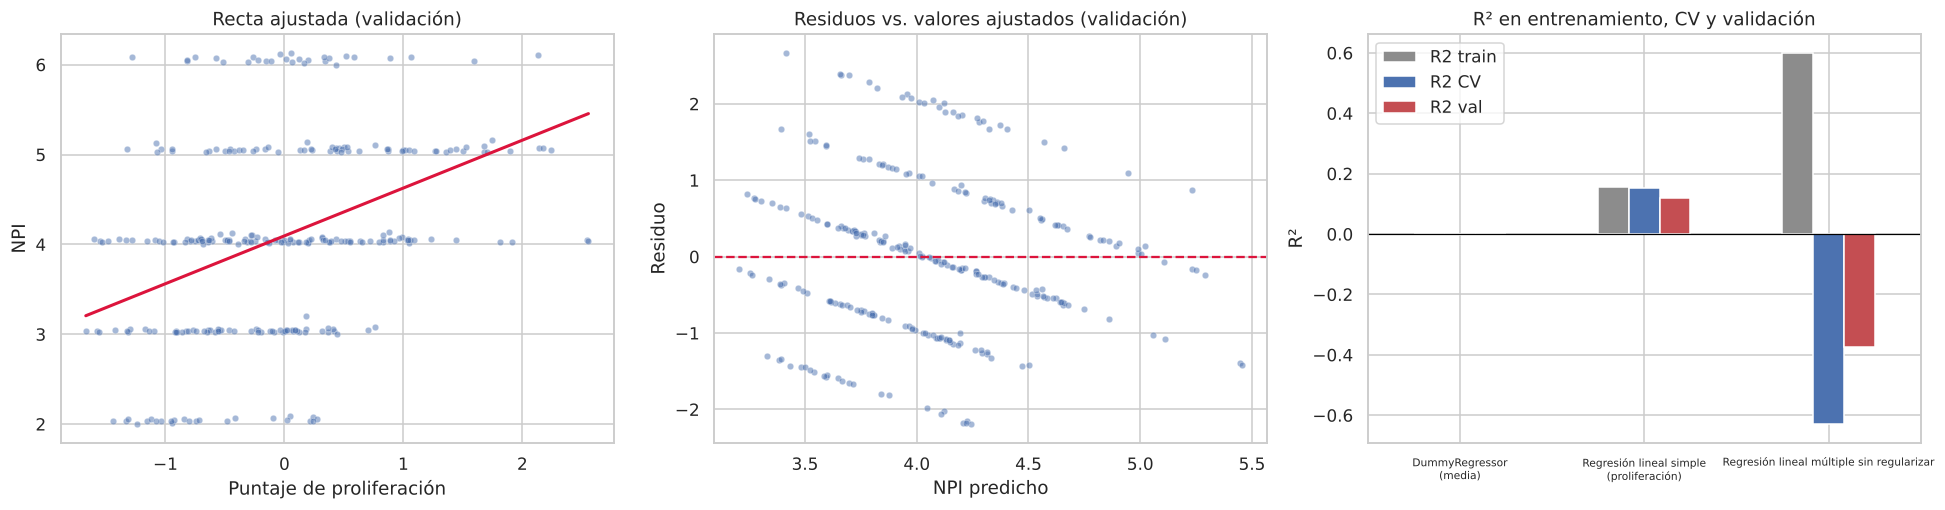

Normalidad de residuos (Shapiro-Wilk, validación): p = 0.0111


In [8]:
lin, cols = reg_fitted["Regresión lineal simple (proliferación)"]
coef = lin.named_steps["model"].coef_[0]
scale = lin.named_steps["scale"].scale_[0]
print(f"Pendiente: {coef:.3f} puntos de NPI por desviación estándar del puntaje "
      f"({coef / scale:.3f} por unidad de puntaje); intercepto: {lin.named_steps['model'].intercept_:.3f}")

pred_va = lin.predict(va_reg[cols])
resid = va_reg[y_reg] - pred_va
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
sns.scatterplot(x=va_reg["proliferation_score"], y=va_reg[y_reg], alpha=.5, s=18, ax=axes[0])
xs = np.linspace(va_reg["proliferation_score"].min(), va_reg["proliferation_score"].max(), 50)
axes[0].plot(xs, lin.predict(pd.DataFrame({"proliferation_score": xs})), color="crimson", lw=2)
axes[0].set(title="Recta ajustada (validación)", xlabel="Puntaje de proliferación", ylabel="NPI")
sns.scatterplot(x=pred_va, y=resid, alpha=.5, s=18, ax=axes[1])
axes[1].axhline(0, color="crimson", ls="--")
axes[1].set(title="Residuos vs. valores ajustados (validación)", xlabel="NPI predicho", ylabel="Residuo")
plot_df = reg_table[["R2 train", "R2 CV", "R2 val"]].rename(index=lambda s: s.replace(" (", "\n("))
plot_df.plot(kind="bar", ax=axes[2], rot=0, color=["#8C8C8C", "#4C72B0", "#C44E52"])
axes[2].axhline(0, color="black", lw=.8)
axes[2].set(title="R² en entrenamiento, CV y validación", ylabel="R²", xlabel="")
axes[2].tick_params(axis="x", labelsize=7)
plt.tight_layout()
savefig("18_baseline_regresion")
plt.show()
print(f"Normalidad de residuos (Shapiro-Wilk, validación): p = {stats.shapiro(resid).pvalue:.3g}")

## 7. Modelo base de clasificación (subtipo PAM50)
Referencias, de menor a mayor complejidad:

* **DummyClassifier (clase más frecuente)** y **DummyClassifier (estratificado)**: pisos de azar.
* **Regresión logística con receptores clínicos:** solo ER, PR y HER2, que es lo que se usa en la práctica clínica cuando no hay perfil molecular. Mide cuánto aporta la genómica.
* **Regresión logística básica:** todos los predictores, parámetros por defecto (C = 1) y el tratamiento de desbalance elegido en la sección 5.

In [9]:
print("Tratamiento de desbalance usado en la logística básica:", best_strategy)
cw = "balanced" if best_strategy.startswith("class_weight") else None

va_clf = clf_df[clf_df.split == "val"]
receptors = ["er_status", "pr_status", "her2_status"]
clf_models = {
    "Dummy (clase más frecuente)": (Pipeline([("model", DummyClassifier(strategy="most_frequent"))]), ["age_at_diagnosis"]),
    "Dummy (estratificado)": (Pipeline([("model", DummyClassifier(strategy="stratified", random_state=SEED))]), ["age_at_diagnosis"]),
    "Logística: receptores ER/PR/HER2": (Pipeline([("pre", build_preprocessor({"nom": receptors})),
                                                   ("model", logreg(class_weight="balanced"))]), receptors),
    "Logística básica: todos los predictores": (
        strategies[best_strategy] if best_strategy.startswith("SMOTE") else
        Pipeline([("pre", build_preprocessor(FS["classification"])), ("model", logreg(class_weight=cw))]), clf_cols),
}
clf_rows, clf_fitted = [], {}
for name, (pipe, cols) in clf_models.items():
    cvres = cv_classification(pipe, tr_clf[cols], tr_clf[y_clf])
    pipe.fit(tr_clf[cols], tr_clf[y_clf])
    clf_fitted[name] = (pipe, cols)
    classes = pipe.classes_
    m_tr = classification_metrics(tr_clf[y_clf], pipe.predict(tr_clf[cols]), pipe.predict_proba(tr_clf[cols]), classes)
    m_va = classification_metrics(va_clf[y_clf], pipe.predict(va_clf[cols]), pipe.predict_proba(va_clf[cols]), classes)
    clf_rows.append({"modelo": name, "F1 train": m_tr["F1_macro"],
                     "F1 CV": cvres["CV_test_F1_macro_mean"], "F1 CV (desv.)": cvres["CV_test_F1_macro_std"],
                     "F1 val": m_va["F1_macro"], "Accuracy val": m_va["Accuracy"],
                     "Bal. Acc. val": m_va["Balanced_Accuracy"], "Precision val": m_va["Precision_macro"],
                     "Recall val": m_va["Recall_macro"], "AUC-ROC CV": cvres["CV_test_AUC_ROC_ovr_mean"],
                     "AUC-ROC val": m_va["AUC_ROC_ovr"]})
clf_table = pd.DataFrame(clf_rows).set_index("modelo")
clf_table

Tratamiento de desbalance usado en la logística básica: class_weight = balanced


,F1 train,F1 CV,F1 CV (desv.),F1 val,Accuracy val,Bal. Acc. val,Precision val,Recall val,AUC-ROC CV,AUC-ROC val
modelo,,,,,,,,,,
Dummy (clase más frecuente),0.088,0.088,0.000,0.088,0.359,0.167,0.060,0.167,0.500,0.500
Dummy (estratificado),0.171,0.187,0.024,0.178,0.246,0.179,0.178,0.179,0.512,0.509
Logística: receptores ER/PR/HER2,0.351,0.351,0.023,0.376,0.507,0.421,0.342,0.421,0.738,0.723
Logística básica: todos los predictores,1.000,0.698,0.019,0.755,0.782,0.757,0.756,0.757,0.943,0.959


Reporte por clase (validación), regresión logística básica:


,precision,recall,f1-score,support
LumA,0.824,0.824,0.824,102.000
LumB,0.803,0.768,0.785,69.000
Her2,0.692,0.818,0.750,33.000
Basal,0.828,0.800,0.814,30.000
claudin-low,0.759,0.759,0.759,29.000
Normal,0.632,0.571,0.600,21.000
accuracy,0.782,0.782,0.782,0.782
macro avg,0.756,0.757,0.755,284.000
weighted avg,0.783,0.782,0.781,284.000


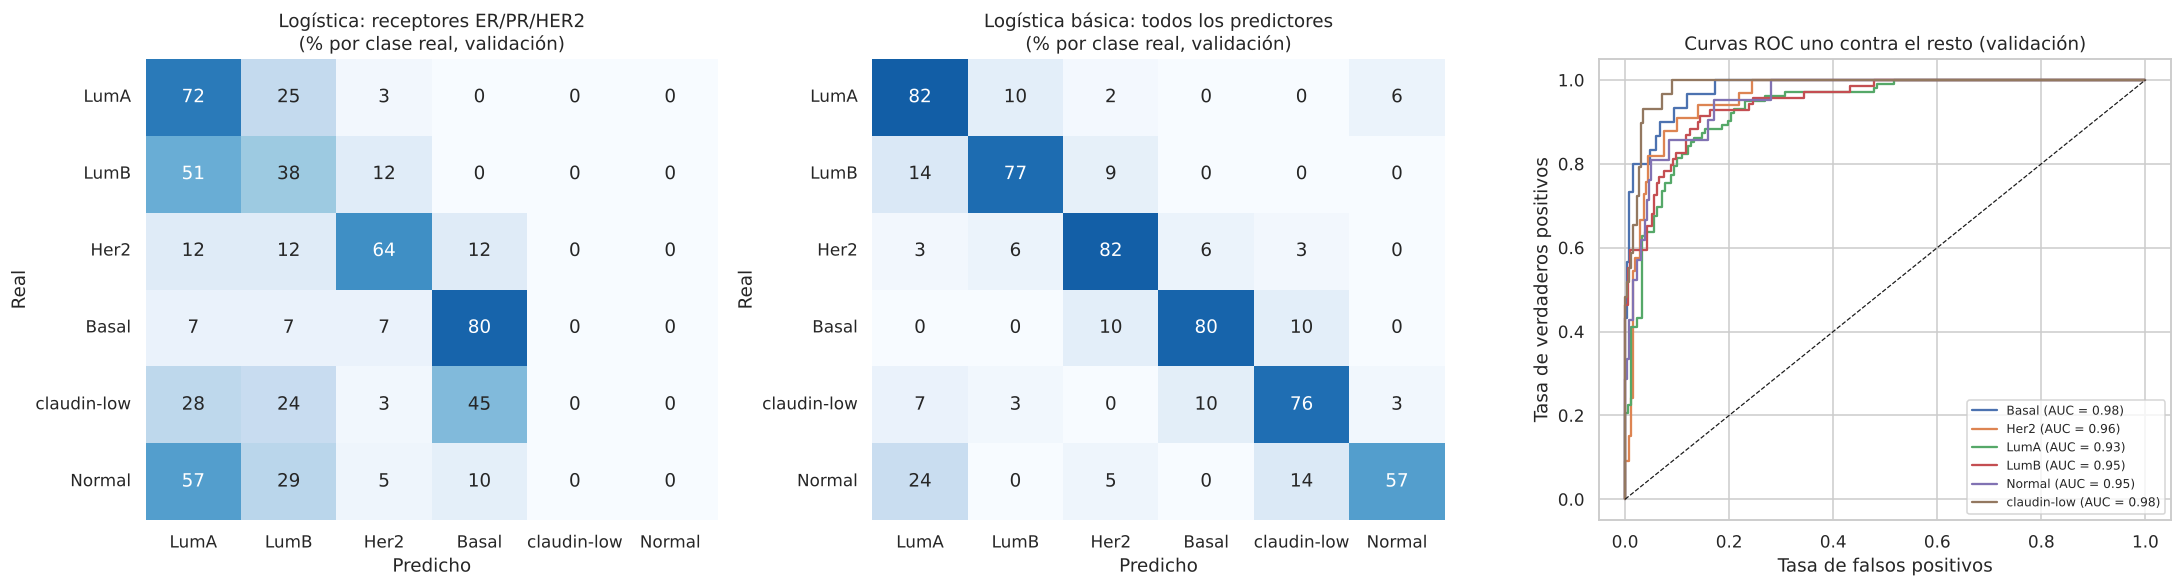

In [10]:
best_clf, cols = clf_fitted["Logística básica: todos los predictores"]
pred = best_clf.predict(va_clf[cols])
print("Reporte por clase (validación), regresión logística básica:")
display(pd.DataFrame(classification_report(va_clf[y_clf], pred, labels=CLASS_ORDER, output_dict=True,
                                           zero_division=0)).T.round(3))

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, key in zip(axes[:2], ["Logística: receptores ER/PR/HER2", "Logística básica: todos los predictores"]):
    pipe, c = clf_fitted[key]
    cm = confusion_matrix(va_clf[y_clf], pipe.predict(va_clf[c]), labels=CLASS_ORDER, normalize="true")
    sns.heatmap(cm * 100, annot=True, fmt=".0f", cmap="Blues", xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER,
                ax=ax, cbar=False, vmin=0, vmax=100)
    ax.set(title=f"{key}\n(% por clase real, validación)", xlabel="Predicho", ylabel="Real")
proba = best_clf.predict_proba(va_clf[cols])
Y = label_binarize(va_clf[y_clf], classes=best_clf.classes_)
for i, c in enumerate(best_clf.classes_):
    fpr, tpr, _ = roc_curve(Y[:, i], proba[:, i])
    axes[2].plot(fpr, tpr, label=f"{c} (AUC = {auc(fpr, tpr):.2f})")
axes[2].plot([0, 1], [0, 1], "k--", lw=.8)
axes[2].set(title="Curvas ROC uno contra el resto (validación)", xlabel="Tasa de falsos positivos",
            ylabel="Tasa de verdaderos positivos")
axes[2].legend(fontsize=8)
plt.tight_layout()
savefig("19_baseline_clasificacion")
plt.show()

## 8. Diagnóstico de sobreajuste
La regresión logística básica alcanza un desempeño perfecto en entrenamiento: con cerca de 590 predictores y 1.300 pacientes, puede separar casi cualquier partición. La curva de aprendizaje muestra si la brecha entre entrenamiento y validación cruzada se cierra al aumentar los datos (alta varianza) o si ambas curvas se estancan juntas (alto sesgo).

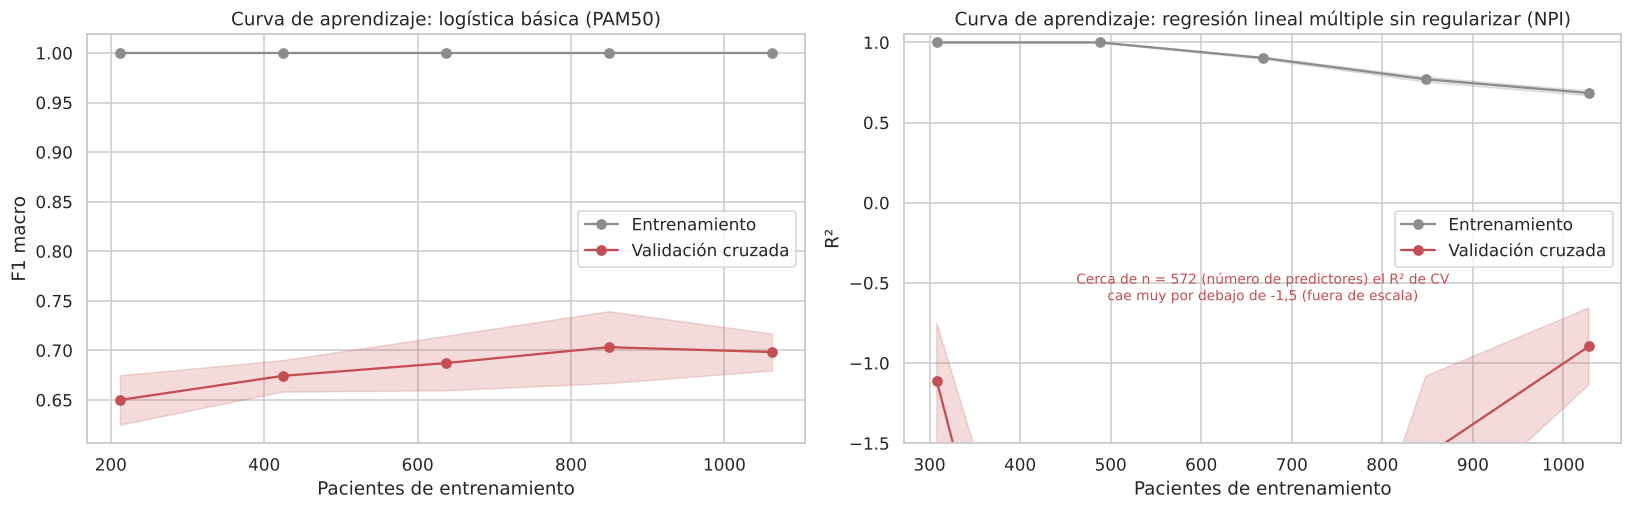

,brecha train - CV
Logística básica (F1 macro),0.302
Lineal múltiple sin regularizar (R²),1.229
Lineal simple (R²),0.005


In [11]:
sizes_lc, tr_scores, cv_scores = learning_curve(
    clf_models["Logística básica: todos los predictores"][0], X_tr_clf, y_tr_clf, cv=cv, scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1, shuffle=True, random_state=SEED)
lin_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("model", LinearRegression())])
ols_pipe = reg_models["Regresión lineal múltiple sin regularizar"][0]
sizes_r, tr_r, cv_r = learning_curve(ols_pipe, tr_reg[reg_cols], tr_reg[y_reg], cv=5, scoring="r2",
                                     train_sizes=np.linspace(0.3, 1.0, 5), n_jobs=-1, shuffle=True, random_state=SEED)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, (s, a, b, title, ylab) in zip(axes, [
        (sizes_lc, tr_scores, cv_scores, "Curva de aprendizaje: logística básica (PAM50)", "F1 macro"),
        (sizes_r, tr_r, cv_r, "Curva de aprendizaje: regresión lineal múltiple sin regularizar (NPI)", "R²")]):
    for sc, lab, col in [(a, "Entrenamiento", "#8C8C8C"), (b, "Validación cruzada", "#C44E52")]:
        ax.plot(s, sc.mean(axis=1), marker="o", label=lab, color=col)
        ax.fill_between(s, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), alpha=.2, color=col)
    ax.set(title=title, xlabel="Pacientes de entrenamiento", ylabel=ylab)
    ax.legend()
axes[1].set_ylim(-1.5, 1.05)
axes[1].text(0.5, 0.35, f"Cerca de n = {len(reg_cols)} (número de predictores) el R² de CV\ncae muy por debajo de -1,5 (fuera de escala)",
             transform=axes[1].transAxes, ha="center", fontsize=9, color="#C44E52")
plt.tight_layout()
savefig("20_curvas_aprendizaje")
plt.show()
gap = pd.DataFrame({
    "brecha train - CV": [clf_table.loc["Logística básica: todos los predictores", "F1 train"] - clf_table.loc["Logística básica: todos los predictores", "F1 CV"],
                          reg_table.loc["Regresión lineal múltiple sin regularizar", "R2 train"] - reg_table.loc["Regresión lineal múltiple sin regularizar", "R2 CV"],
                          reg_table.loc["Regresión lineal simple (proliferación)", "R2 train"] - reg_table.loc["Regresión lineal simple (proliferación)", "R2 CV"]]},
    index=["Logística básica (F1 macro)", "Lineal múltiple sin regularizar (R²)", "Lineal simple (R²)"])
gap

## 9. Umbral mínimo de desempeño

In [12]:
reg_base = reg_table.loc["Regresión lineal simple (proliferación)"]
clf_base = clf_table.loc["Logística básica: todos los predictores"]
thresholds = pd.DataFrame([
    {"tarea": "Regresión (NPI)", "modelo base": "Regresión lineal simple (proliferación)",
     "métrica principal": "RMSE (y R²)", "valor CV": f"{reg_base['RMSE CV']:.3f} (R² {reg_base['R2 CV']:.3f})",
     "valor validación": f"{reg_base['RMSE val']:.3f} (R² {reg_base['R2 val']:.3f})",
     "meta SMART (Fase 1)": "R² ≥ 0,20 y menor RMSE que el base"},
    {"tarea": "Clasificación (PAM50)", "modelo base": "Regresión logística básica",
     "métrica principal": "F1 macro (y AUC-ROC)", "valor CV": f"{clf_base['F1 CV']:.3f} (AUC {clf_base['AUC-ROC CV']:.3f})",
     "valor validación": f"{clf_base['F1 val']:.3f} (AUC {clf_base['AUC-ROC val']:.3f})",
     "meta SMART (Fase 1)": "F1 macro ≥ 0,75 en prueba, superar al base en CV y brecha train-CV < 0,15"},
]).set_index("tarea")
display(thresholds)

metrics_out = pd.concat([reg_table.assign(tarea="regresión"), clf_table.assign(tarea="clasificación")])
metrics_out.to_csv(config.METRICS_DIR / "baseline_metrics.csv", encoding="utf-8-sig")
with open(config.METRICS_DIR / "baseline_thresholds.json", "w", encoding="utf-8") as f:
    json.dump({"regression": {"model": "LinearRegression(proliferation_score)", "RMSE_cv": reg_base["RMSE CV"],
                              "R2_cv": reg_base["R2 CV"], "RMSE_val": reg_base["RMSE val"], "R2_val": reg_base["R2 val"]},
               "classification": {"model": "LogisticRegression(all features)", "imbalance": best_strategy,
                                  "F1_macro_cv": clf_base["F1 CV"], "F1_macro_val": clf_base["F1 val"],
                                  "AUC_cv": clf_base["AUC-ROC CV"], "AUC_val": clf_base["AUC-ROC val"]}},
              f, ensure_ascii=False, indent=1)
print("Guardado en reports/metrics/: baseline_metrics.csv y baseline_thresholds.json")

,modelo base,métrica principal,valor CV,valor validación,meta SMART (Fase 1)
tarea,,,,,
Regresión (NPI),Regresión lineal simple (proliferación),RMSE (y R²),0.995 (R² 0.153),1.025 (R² 0.121),"R² ≥ 0,20 y menor RMSE que el base"
Clasificación (PAM50),Regresión logística básica,F1 macro (y AUC-ROC),0.698 (AUC 0.943),0.755 (AUC 0.959),"F1 macro ≥ 0,75 en prueba, superar al base en ..."


Guardado en reports/metrics/: baseline_metrics.csv y baseline_thresholds.json


## 10. Conclusiones y siguientes pasos

1. **Partición reproducible y sin fuga.** Se regenera de forma idéntica desde los datos crudos, ninguna paciente aparece en dos subconjuntos y la distribución del NPI es equivalente entre ellos (Kolmogorov-Smirnov, p = 0,94 y 0,93). Los tamaños son 1.285/280/281 pacientes para regresión y 1.328/284/285 para clasificación.
2. **Desbalance moderado.** La razón entre la clase mayoritaria (LumA) y la minoritaria (Normal) es 4,85. Las tres estrategias evaluadas empatan en F1 macro (0,697 a 0,701, dentro de una desviación estándar). Se eligió `class_weight="balanced"` porque mejora el recall de la clase Normal (0,449 → 0,480) sin crear datos sintéticos en un espacio de casi 600 dimensiones, donde la interpolación de SMOTE es menos confiable.
3. **Modelo base de regresión.** La regresión lineal simple con el puntaje de proliferación explica el 15,3 % de la varianza del NPI en CV (R² = 0,153 ± 0,020; 0,121 en validación) y reduce el RMSE de validación de 1,094 (Dummy) a 1,025. Cada desviación estándar del puntaje suma 0,43 puntos de NPI. Los residuos forman bandas diagonales porque el NPI es casi discreto (sección 5 del cuaderno 02) y no son normales (Shapiro-Wilk, p = 0,011).
4. **La regularización es imprescindible.** La regresión lineal múltiple sin regularizar pasa de R² = 0,60 en entrenamiento a −0,63 en CV y −0,37 en validación: con 572 predictores y 1.285 pacientes, memoriza el ruido. Esto justifica Lasso, Ridge o ElasticNet en la fase 3.
5. **Modelo base de clasificación.** La regresión logística básica alcanza F1 macro = 0,698 ± 0,019 en CV y 0,755 en validación, con AUC-ROC = 0,959. Supera con amplitud al Dummy (F1 = 0,088) y a la logística con solo receptores clínicos (F1 = 0,376), que no reconoce ningún tumor claudin-low ni Normal: la genómica aporta la mayor parte de la capacidad discriminante. La clase más difícil es Normal-like (F1 = 0,60; el 24 % se confunde con LumA).
6. **Sobreajuste del modelo base.** La logística básica obtiene F1 = 1,00 en entrenamiento (brecha de 0,30 frente a CV), y su curva de aprendizaje sigue subiendo con más datos: es un problema de **alta varianza**, que la fase 3 debe atacar con regularización (ajuste de C, L1/L2), reducción de dimensión o modelos de ensamble.

**Umbrales que la fase 3 debe superar** (guardados en `reports/metrics/baseline_thresholds.json`):

| Tarea | Métrica | Base en CV | Base en validación |
|---|---|---|---|
| Regresión (NPI) | RMSE / R² | 0,995 / 0,153 | 1,025 / 0,121 |
| Clasificación (PAM50) | F1 macro / AUC-ROC | 0,698 / 0,943 | 0,755 / 0,959 |

**Relación con los objetivos SMART.** La meta de clasificación exige tres condiciones que el modelo base no cumple: F1 macro ≥ 0,75 en prueba, superar su F1 en validación cruzada (0,698) y bajar la brecha de sobreajuste de 0,30 a menos de 0,15. En regresión, el modelo base (R² = 0,12-0,15) aún no alcanza la meta de R² ≥ 0,20.

**Siguiente paso (fase 3):** Ridge, Lasso o ElasticNet y Random Forest o Gradient Boosting para el NPI; dos clasificadores (SVM y Random Forest o XGBoost) con búsqueda de hiperparámetros por validación cruzada; K-Means (codo y silueta) y clustering jerárquico o DBSCAN sobre la expresión génica reducida por PCA; MLP en PyTorch; e interpretabilidad con SHAP o importancia de variables. La comparación final se hará una sola vez sobre el conjunto de prueba.